# Практическая работа №9. Индексы и производительность в PostgreSQL
## Конспект пары для преподавателя (по порядку проведения занятия)

### План пары (90 минут)
| Время | Этап пары | Что показывает преподаватель | Что делают студенты |
| :--- | :--- | :--- | :--- |
| **До пары** | **Этап 0. Подготовка** | Генерирует таблицу `orders` (200k строк) в базе `club_demo` (ячейкой ниже или скриптом `demo/01_demo_setup.sql`). | — |
| **00–15 мин** | **Этап 1. Зачем нужны индексы** | Идея B-Tree на примере оглавления книги. Почему на 100 строках индекс не работает (`Seq Scan`). Как читать `EXPLAIN ANALYZE`. | Подключаются к своей базе `club_varXX` (в DBeaver или Google Colab). |
| **15–35 мин** | **Этап 2. Полигон 200k и первый индекс** | Выполняет Шаг 1 и Шаг 2 из `demo/02_demo_experiments.sql` (`Seq Scan` $\to$ `Index Scan`), показывает визуальный план в DBeaver (`Ctrl+Shift+E`). | Генерируют `orders` у себя, снимают первый замер «До» / «После». |
| **35–55 мин** | **Этап 3. Сортировка, цена `INSERT` и Partial Index** | Показывает исчезновение узла `Sort` на составном индексе, падение скорости `INSERT` при 3 индексах и сравнение `pg_relation_size` для частичного индекса. | Выполняют Шаги 3, 4 и 5, заносят свои цифры в сводную таблицу. |
| **55–90 мин** | **Этап 4. Завершение и приемка** | Проверяет сводные таблицы замеров и ответы на 4 контрольных вопроса. | Доделывают замеры, отвечают на вопросы и сдают отчет. |

---
## Этап 0 (До пары). Подготовка демо-базы `club_demo`

Запустите скрипт `demo/01_demo_setup.sql` в DBeaver на базе `club_demo` **или** впишите пароль `PG_PASS` в ячейку ниже для автоматического развертывания полигона на сервере.
*(Если `PG_PASS` не задан, ячейка пропустит подключение к VPS, а демонстрационные ячейки ниже запустятся локально на SQLite + `matplotlib`).*

In [1]:
import os
import sqlite3
import time
import random
import pandas as pd
import matplotlib.pyplot as plt

PG_HOST = os.environ.get("PG_HOST", "81.30.105.12")
PG_PORT = os.environ.get("PG_PORT", "5432")
PG_DB   = os.environ.get("PG_DB",   "club_demo")
PG_USER = os.environ.get("PG_USER", "postgres")
PG_PASS = os.environ.get("PG_PASS", "NDS_Password")

if PG_PASS:
    import psycopg2
    conn_pg = psycopg2.connect(host=PG_HOST, port=PG_PORT, database=PG_DB, user=PG_USER, password=PG_PASS)
    conn_pg.autocommit = True
    with open(os.path.join("demo", "01_demo_setup.sql"), "r", encoding="utf-8") as f:
        sql_setup = f.read()
    with conn_pg.cursor() as cur:
        cur.execute(sql_setup)
        cur.execute("SELECT COUNT(*) FROM orders;")
        print(f"[OK] В базе PostgreSQL ({PG_DB}) создана таблица orders: {cur.fetchone()[0]} строк.")
    conn_pg.close()
else:
    print("[Инфо] PG_PASS не задан — далее в ноутбуке используется локальная имитация на 100 000 строк.")

[OK] В базе PostgreSQL (club_demo) создана таблица orders: 200000 строк.


---
## Этап 1 (00–15 мин). Основные понятия: `EXPLAIN ANALYZE`, `Seq Scan` и `Index Scan`

### 1.1. Что выписать на доску
1. **Индекс (B-Tree)** — отсортированное поисковое дерево с адресами строк таблицы (как алфавитный указатель в конце толстой книги).
2. **`Seq Scan` (Sequential Scan)** — последовательное чтение всех блоков таблицы подряд (перелистывание всей книги от первой страницы до последней).
3. **`Index Scan` / `Bitmap Index Scan`** — поиск адреса нужных строк в B-Tree и чтение только нужных страниц таблицы.
4. **`EXPLAIN` против `EXPLAIN ANALYZE`:**
   * `EXPLAIN` — запрос **не выполняется**; планировщик лишь оценивает примерную стоимость (`cost`) и число строк (`rows`).
   * `EXPLAIN ANALYZE` — запрос **выполняется реально**, и в конце выводится точное время **`Execution Time: ... ms`**.

### 1.2. Важный нюанс: почему на 100 строках индекс бесполезен?
Если таблица занимает всего 1 страницу памяти (8 КБ), прочитать её целиком за 1 операцию быстрее, чем сначала читать страницу индекса, а потом переходить на страницу таблицы. Поэтому в файле `demo/02_demo_experiments.sql` первым идет мини-тест на 100 строках (`tiny_test`), где PostgreSQL игнорирует индекс и выбирает `Seq Scan`.

---
## Этап 2 (15–35 мин). Полигон 200 000 строк и первый замер (`Seq Scan` $\to$ `Index Scan`)

### Что показываем в DBeaver (скрипт `demo/02_demo_experiments.sql`)
1. Выполняем `EXPLAIN ANALYZE SELECT * FROM orders WHERE user_id = 500;` $\to$ видим **`Seq Scan on orders`** и время ~20–40 мс.
2. Показываем горячую клавишу DBeaver **`Ctrl + Shift + E`** (Explain Execution Plan) на обычном `SELECT` — студенты видят графическую схему плана.
3. Выполняем `CREATE INDEX idx_orders_user_id ON orders(user_id); ANALYZE orders;`.
4. Повторяем запрос $\to$ видим **`Bitmap Index Scan` / `Index Scan`** и время ~0.1–0.3 мс.

### Локальная демонстрация замера и графика (работает без сервера):

План ДО индекса   : SCAN orders | Среднее время: 2.738 мс
План ПОСЛЕ индекса: SEARCH orders USING INDEX idx_orders_user_id (user_id=?) | Среднее время: 0.042 мс
Ускорение: в 64.9 раз


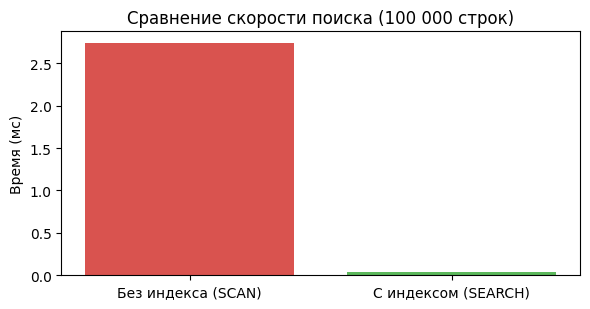

In [2]:
# Локальная модель таблицы на 100 000 строк (для проверки цифр и графика прямо в ноутбуке)
conn_sim = sqlite3.connect(":memory:")
conn_sim.execute("CREATE TABLE orders (order_id INTEGER PRIMARY KEY, user_id INTEGER, order_date TEXT, status TEXT, amount REAL);")

rng = random.Random(42)
rows_sim = [
    (i, rng.randint(1, 2000), f"2026-{(i % 12) + 1:02d}-{(i % 28) + 1:02d}", "cancelled" if i % 20 == 0 else "delivered", round(rng.uniform(100, 5000), 2))
    for i in range(1, 100001)
]
conn_sim.executemany("INSERT INTO orders VALUES (?, ?, ?, ?, ?)", rows_sim)
conn_sim.commit()

def measure_ms(conn, sql, repeats=15):
    times = []
    for _ in range(repeats):
        t0 = time.perf_counter()
        conn.execute(sql).fetchall()
        times.append((time.perf_counter() - t0) * 1000.0)
    return sum(times) / len(times)

q_test = "SELECT * FROM orders WHERE user_id = 500;"
plan_before = conn_sim.execute("EXPLAIN QUERY PLAN " + q_test).fetchall()
ms_before = measure_ms(conn_sim, q_test)

conn_sim.execute("CREATE INDEX idx_orders_user_id ON orders(user_id);")
plan_after = conn_sim.execute("EXPLAIN QUERY PLAN " + q_test).fetchall()
ms_after = measure_ms(conn_sim, q_test)

print("План ДО индекса   :", plan_before[0][-1], f"| Среднее время: {ms_before:.3f} мс")
print("План ПОСЛЕ индекса:", plan_after[0][-1],  f"| Среднее время: {ms_after:.3f} мс")
print(f"Ускорение: в {ms_before / ms_after:.1f} раз")

plt.figure(figsize=(6, 3.2))
plt.bar(["Без индекса (SCAN)", "С индексом (SEARCH)"], [ms_before, ms_after], color=["#d9534f", "#5cb85c"])
plt.ylabel("Время (мс)")
plt.title("Сравнение скорости поиска (100 000 строк)")
plt.tight_layout()
plt.show()
conn_sim.close()

---
## Этап 3 (35–55 мин). Три главных инженерных урока

### 3.1. Составной индекс убирает шаг сортировки (`Sort`)
* При одном индексе `orders(user_id)` запрос `WHERE user_id = 500 ORDER BY order_date DESC LIMIT 5` сначала находит все заказы пользователя, а затем запускает узел **`Sort (top-N heapsort)`**.
* После `CREATE INDEX idx_orders_user_date ON orders(user_id, order_date DESC);` строки внутри дерева уже лежат в нужном порядке — узел **`Sort` исчезает из плана**.

### 3.2. Цена индексов — замедление записи (`INSERT`)
* При вставке 50 000 строк в таблицу `bench_no_idx` (без индексов) и `bench_with_idx` (3 индекса) вторая вставка идет в **3–5 раз медленнее**, потому что каждое дерево B-Tree приходится перебалансировать при записи.
* Вывод: **нельзя индексировать все столбцы подряд**, особенно в таблицах с частой записью (логи, телеметрия).

### 3.3. Частичный индекс (`Partial Index`)
* Если статус `'cancelled'` имеют только 5% строк, команда:
  `CREATE INDEX idx_orders_cancelled ON orders(user_id) WHERE status = 'cancelled';`
  индексирует только эти 5% строк и занимает на диске в **10–20 раз меньше места**, чем полный индекс по `user_id`.

---
## Этап 4 (55–90 мин). Контрольные вопросы и приемка работ

### Что проверяется у студента
1. Файл `lab9_varXX.sql` или выполненный ноутбук `Шаблон_для_студента_Colab.ipynb` с индивидуальным `my_user_id = 100 + XX * 17`.
2. Заполненная сводная таблица с реальными замерами «До» и «После» по всем 4 экспериментам.
3. Краткие ответы на 4 контрольных вопроса:
   * *Чем `EXPLAIN` отличается от `EXPLAIN ANALYZE`?* (`EXPLAIN` — прогноз без запуска, `EXPLAIN ANALYZE` — реальный запуск и замер времени).
   * *Почему на 100 строках используется `Seq Scan`?* (Чтение 1 страницы целиком быстрее перехода «индекс $\to$ таблица»).
   * *Когда нужен составной индекс, а когда частичный?* (Составной — под частую пару фильтр + сортировка `ORDER BY`; частичный — для редкого подмножества строк, например статусов ошибок или отмен).
   * *Почему нельзя индексировать каждый столбец?* (Замедляются `INSERT`/`UPDATE`/`DELETE` и расходуется место на диске и в ОЗУ сервера).